# Experiment 2 — DAIN (multivariate, target `num_jobs`)

Backbones: **LSTM + GRU**.

Derived from `lstm-dain.ipynb` in the KSAK repo. The normalization layer, the model,
the split, the sliding-window tuning and the Iverson metrics are unchanged.

Changes from the repo notebook:

- a **CONFIG cell** at the top (dataset, feature mode, target, seed, epochs, windows)
- **seeding** added (the repo's DAIN notebook had none, unlike `lstm-edain.ipynb`)
- a **`FEATURE_MODE` switch**, copied from `lstm-vanilla.ipynb` — the DAIN notebook
  had none and could only run multivariate
- `dataset = df.values` -> `data.values`, so the feature selection is actually used
- **GRU kept**, as in the repo notebook
- appends one row per backbone to `results.csv`

In [1]:
# ============================================================
# EXPERIMENT 2 — DAIN | multivariate | target = num_jobs
# Backbones: LSTM + GRU
# ============================================================
# Switch DATASET between '09' and '25' and re-run the notebook.
# The .swf files sit in this same folder.
DATASET = '09'                     # '09' | '25'

DATA_FILES = {
    '09': '09-SDSC-SP2-1998-4.2-cln.swf',
    '25': '25-LLNL-uBGL-2006-2.swf',
}
DATASET_PATH = DATA_FILES[DATASET]

FEATURE_MODE = 'multivariate'
TARGET_COL   = 'num_jobs'

RUN_NAME    = f'02-dain-multi-numjobs-log{DATASET}'
RESULTS_CSV = 'results.csv'

SLICE_MINUTES     = 15
WINDOW_CANDIDATES = [30, 60, 90, 120]
BATCH_SIZE        = 32
EPOCHS            = 50
SEED              = 42

# --- reproducibility -----------------------------------------------------
import os, random
import numpy as np
import tensorflow as tf

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'Run: {RUN_NAME}')
print(f'Data: {DATASET_PATH}')
print(f'Feature mode: {FEATURE_MODE} | Target: {TARGET_COL} | Seed: {SEED}')


Run: 02-dain-multi-numjobs-log09
Data: 09-SDSC-SP2-1998-4.2-cln.swf
Feature mode: multivariate | Target: num_jobs | Seed: 42


### DAIN implementation note
This notebook translates the original Passalis et al. DAIN layer from PyTorch to TensorFlow/Keras. The original implementation exposes `mean_lr`, `scale_lr`, and `gate_lr`; here they are used as separate optimizer groups for those DAIN parameters.
Original implementation: https://github.com/passalis/dain/blob/master/dain.py


## Step 1: Library Imports

In [2]:
# Import necessary libraries for data
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tabulate import tabulate
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.style.use("fivethirtyeight")
%matplotlib inline
from datetime import datetime

## Step 2: Data Preparation and Splitting


In [3]:
# DATASET_PATH, SLICE_MINUTES come from the CONFIG cell.
ALL_FEATURE_COLS = ['num_jobs', 'total_allocated_proc', 'std_allocated_proc', 'total_run_time', 'std_run_time', 'avg_allocated_proc', 'avg_run_time']

# Standard Workload Format columns (same list as last sprint's notebook).
SWF_LABELS = (
    "job_id", "submit_time", "wait_time", "run_time", "allocated_proc", "cpu_time",
    "used_mem", "requested_proc", "requested_time", "requested_mem", "status",
    "user_id", "group_id", "executable_id", "queue_id", "partition_id",
    "preceding_job_id", "think_time",
)

def preprocess_data(path, slice_minutes):
    jobs = pd.read_csv(path, header=None, names=SWF_LABELS, delimiter=r"\s+",
                       comment=";", usecols=['submit_time', 'run_time', 'allocated_proc'])
    jobs = jobs.astype({'run_time': 'float64', 'allocated_proc': 'float64'})

    jobs['submit_time'] = jobs['submit_time'] - jobs['submit_time'].min()

    jobs = jobs[jobs['run_time'] > 0].copy()
    jobs['slice'] = (jobs['submit_time'] // (slice_minutes * 60)).astype('int64')

    data_agg = jobs.groupby('slice').agg(
        num_jobs=('run_time', 'size'),
        total_run_time=('run_time', 'sum'),
        std_run_time=('run_time', 'std'),
        total_allocated_proc=('allocated_proc', 'sum'),
        std_allocated_proc=('allocated_proc', 'std'),
    )
    data_agg['avg_allocated_proc'] = data_agg['total_allocated_proc'] / data_agg['num_jobs']
    data_agg['avg_run_time'] = data_agg['total_run_time'] / data_agg['num_jobs']

    full_range = np.arange(data_agg.index.min(), data_agg.index.max() + 1)
    data_agg = data_agg.reindex(full_range, fill_value=0).fillna(0)

    return data_agg.reset_index(drop=True)[ALL_FEATURE_COLS]


df = preprocess_data(DATASET_PATH, SLICE_MINUTES)
df

,num_jobs,total_allocated_proc,std_allocated_proc,total_run_time,std_run_time,avg_allocated_proc,avg_run_time
0,2,2.0,0.0,54997.0,1877.368504,1.0,27498.5
1,1,8.0,0.0,8071.0,0.000000,8.0,8071.0
2,0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0,0.0,0.0,0.0,0.000000,0.0,0.0
4,0,0.0,0.0,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...
70013,0,0.0,0.0,0.0,0.000000,0.0,0.0
70014,0,0.0,0.0,0.0,0.000000,0.0,0.0
70015,0,0.0,0.0,0.0,0.000000,0.0,0.0
70016,0,0.0,0.0,0.0,0.000000,0.0,0.0


In [4]:
# Feature mode switch: 'univariate' uses only the target; 'multivariate' uses all covariates.
target_col = TARGET_COL

MULTIVARIATE_FEATURE_COLS = [
    'num_jobs',
    'total_allocated_proc',
    'std_allocated_proc',
    'total_run_time',
    'std_run_time',
    'avg_allocated_proc',
    'avg_run_time',
]

if FEATURE_MODE == 'univariate':
    feature_cols = [target_col]
elif FEATURE_MODE == 'multivariate':
    feature_cols = list(MULTIVARIATE_FEATURE_COLS)
else:
    raise ValueError("FEATURE_MODE must be 'univariate' or 'multivariate'")

if target_col not in feature_cols:
    raise ValueError(f"target_col '{target_col}' must be included in feature_cols")

data = df[feature_cols].dropna()

target_idx = feature_cols.index(target_col)
n_features = len(feature_cols)

print("Feature mode:", FEATURE_MODE)
print("Features:", feature_cols)
print("Target:", target_col)
print("Number of features:", n_features)
print("Target index:", target_idx)


Feature mode: multivariate
Features: ['num_jobs', 'total_allocated_proc', 'std_allocated_proc', 'total_run_time', 'std_run_time', 'avg_allocated_proc', 'avg_run_time']
Target: num_jobs
Number of features: 7
Target index: 0


### DAIN integrated into the forecasting model
DAIN is implemented in TensorFlow/Keras and runs on each input window inside the LSTM/GRU model.
**Inputs:** DAIN per window. **Target:** train-only global z-score of `num_jobs` (fit on the training split), inverted with the same mean/std after prediction.


In [5]:
# Deep Adaptive Input Normalization (DAIN) translated from the author's PyTorch implementation.
# Source: https://github.com/passalis/dain/blob/master/dain.py
# DAIN is applied inside each forecasting model, per input window.
import tensorflow as tf
from tensorflow.keras.layers import Dense, LSTM, GRU, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

class DAINLayer(tf.keras.layers.Layer):
    """TensorFlow/Keras translation of the original DAIN layer."""
    def __init__(self, mode='adaptive_scale', input_dim=n_features, eps=1e-8, **kwargs):
        super().__init__(**kwargs)
        self.mode = mode; self.input_dim = input_dim; self.eps = eps
        self.mean_layer = Dense(input_dim, use_bias=False,
                                kernel_initializer=tf.keras.initializers.Identity(), name='mean_layer')
        self.scaling_layer = Dense(input_dim, use_bias=False,
                                   kernel_initializer=tf.keras.initializers.Identity(), name='scaling_layer')
        self.gating_layer = Dense(input_dim, use_bias=True,
                                  kernel_initializer='glorot_uniform', bias_initializer='zeros', name='gating_layer')

    def call(self, inputs, return_statistics=False):
        if self.mode is None:
            if return_statistics:
                batch = tf.shape(inputs)[0]
                return inputs, tf.zeros((batch,self.input_dim),inputs.dtype), tf.ones((batch,self.input_dim),inputs.dtype), tf.ones((batch,self.input_dim),inputs.dtype)
            return inputs
        if self.mode not in ('avg','adaptive_avg','adaptive_scale','full'):
            raise ValueError(f'Unknown DAIN mode: {self.mode}')
        x = tf.transpose(inputs, [0,2,1])
        avg = tf.reduce_mean(x, axis=2)
        adaptive_avg = avg; adaptive_std = tf.ones_like(avg); gate = tf.ones_like(avg)
        if self.mode == 'avg':
            x = x - tf.expand_dims(avg,2)
        else:
            adaptive_avg = self.mean_layer(avg)
            x = x - tf.expand_dims(adaptive_avg,2)
            if self.mode in ('adaptive_scale','full'):
                std = tf.sqrt(tf.reduce_mean(tf.square(x), axis=2) + self.eps)
                adaptive_std = self.scaling_layer(std)
                adaptive_std = tf.where(adaptive_std <= self.eps, tf.ones_like(adaptive_std), adaptive_std)
                x = x / tf.expand_dims(adaptive_std,2)
            if self.mode == 'full':
                avg_after_scale = tf.reduce_mean(x, axis=2)
                gate = tf.sigmoid(self.gating_layer(avg_after_scale))
                x = x * tf.expand_dims(gate,2)
        x = tf.transpose(x, [0,2,1])
        return (x, adaptive_avg, adaptive_std, gate) if return_statistics else x

    def normalize_target(self, target, adaptive_avg, adaptive_std, gate, target_idx=0):
        avg = adaptive_avg[:, target_idx:target_idx + 1]
        std = adaptive_std[:, target_idx:target_idx + 1]
        gate_value = gate[:, target_idx:target_idx + 1]
    
        gate_value = tf.maximum(gate_value, self.eps)
    
        return ((target - avg) / std) * gate_value

    def inverse_target(self, normalized_target, adaptive_avg, adaptive_std, gate):
        return (normalized_target / gate) * adaptive_std + adaptive_avg

    def get_config(self):
        config = super().get_config(); config.update({'mode':self.mode,'input_dim':self.input_dim,'eps':self.eps}); return config


In [6]:
def _clone_optimizer_with_lr(optimizer, learning_rate):
    config = optimizer.get_config(); config['learning_rate'] = learning_rate
    return optimizer.__class__.from_config(config)

class DAINForecastModel(tf.keras.Model):
    """DAIN + recurrent forecast model with separate DAIN learning-rate groups."""
    def __init__(self, dain_layer, backbone_layers, target_idx, target_mean, target_std, **kwargs):
        super().__init__(**kwargs)
        self.dain = dain_layer
        self.backbone_layers = backbone_layers
        self.target_idx = target_idx
        # Train-only global target stats (constants; not from the input window).
        self.target_mean = tf.constant(float(target_mean), dtype=tf.float32)
        self.target_std = tf.constant(float(target_std), dtype=tf.float32)
        self.loss_tracker = tf.keras.metrics.Mean(name='loss')

    def call(self, inputs, training=False, return_dain_stats=False):
        x, avg, std, gate = self.dain(inputs, return_statistics=True)
        for layer in self.backbone_layers:
            x = layer(x, training=training)
        return (x, avg, std, gate) if return_dain_stats else x

    def compile(self, optimizer, loss='mean_squared_error', mean_lr=1e-5, gate_lr=1e-3, scale_lr=1e-5, **kwargs):
        super().compile(optimizer=optimizer, **kwargs)
        self.loss_fn = tf.keras.losses.get(loss)
        self.mean_optimizer = _clone_optimizer_with_lr(optimizer, mean_lr)
        self.gate_optimizer = _clone_optimizer_with_lr(optimizer, gate_lr)
        self.scale_optimizer = _clone_optimizer_with_lr(optimizer, scale_lr)
        self.mean_lr = mean_lr
        self.gate_lr = gate_lr
        self.scale_lr = scale_lr

    @property
    def metrics(self):
        return [self.loss_tracker]

    def _split_trainable_variables(self):
        mean_vars = list(self.dain.mean_layer.trainable_variables)
        scale_vars = list(self.dain.scaling_layer.trainable_variables)
        gate_vars = list(self.dain.gating_layer.trainable_variables)
        ids = {id(v) for v in mean_vars + scale_vars + gate_vars}
        main_vars = [v for v in self.trainable_variables if id(v) not in ids]
        return main_vars, mean_vars, scale_vars, gate_vars

    @staticmethod
    def _apply(opt, grads, vars_):
        pairs = [(g, v) for g, v in zip(grads, vars_) if g is not None]
        if pairs:
            opt.apply_gradients(pairs)

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            pred = self(x, training=True, return_dain_stats=False)
            y_norm = (y - self.target_mean) / self.target_std
            loss = self.loss_fn(y_norm, pred)
            if self.losses:
                loss += tf.add_n(self.losses)

        vars_ = self.trainable_variables
        grads = tape.gradient(loss, vars_)
        main, mean, scale, gate = self._split_trainable_variables()
        g = {id(v): gr for v, gr in zip(vars_, grads)}

        self._apply(self.optimizer, [g[id(v)] for v in main], main)
        self._apply(self.mean_optimizer, [g[id(v)] for v in mean], mean)
        self._apply(self.scale_optimizer, [g[id(v)] for v in scale], scale)
        self._apply(self.gate_optimizer, [g[id(v)] for v in gate], gate)

        self.loss_tracker.update_state(loss)
        return {'loss': self.loss_tracker.result()}

    def test_step(self, data):
        x, y = data
        pred = self(x, training=False, return_dain_stats=False)
        y_norm = (y - self.target_mean) / self.target_std
        loss = self.loss_fn(y_norm, pred)
        if self.losses:
            loss += tf.add_n(self.losses)
        self.loss_tracker.update_state(loss)
        return {'loss': self.loss_tracker.result()}

    def predict_with_dain_stats(self, x_data):
        return self(x_data, training=False, return_dain_stats=True)

DAIN_MEAN_LR=1e-5; DAIN_GATE_LR=1e-3; DAIN_SCALE_LR=1e-5


In [7]:
# Convert the dataframe to a numpy array
dataset = data.values.astype(np.float32)

# Split the dataset into training, validation, and test sets
training_data_len = int(np.ceil(len(dataset) * 0.70))
validation_data_len = int(np.ceil(len(dataset) * 0.85))

train_data = dataset[:training_data_len, :]
val_data = dataset[training_data_len:validation_data_len, :]
test_data = dataset[validation_data_len:, :]

print(f"Training Data Length: {len(train_data)}")
print(f"Validation Data Length: {len(val_data)}")
print(f"Test Data Length: {len(test_data)}")


Training Data Length: 49013
Validation Data Length: 10503
Test Data Length: 10502


### Data scaling / normalization
No global DAIN preprocessing is performed. The raw series is kept intact and DAIN is applied inside each forecasting model on every window.


In [8]:
# Keep the raw series intact. DAIN is applied inside each model/window on inputs.
# Target uses a train-only global z-score (no leakage from val/test).
full_data = dataset.astype(np.float32)
train_end = len(train_data)
val_end = train_end + len(val_data)

target_mean = float(train_data[:, target_idx].mean())
target_std = float(max(train_data[:, target_idx].std(), 1e-8))

print('DAIN on inputs; global train-only target z-score.')
print(f"target_mean={target_mean:.6f} | target_std={target_std:.6f}")
print(f"Train boundary: {train_end} | Validation boundary: {val_end} | Total: {len(full_data)}")


DAIN on inputs; global train-only target z-score.
target_mean=0.890580 | target_std=2.401977
Train boundary: 49013 | Validation boundary: 59516 | Total: 70018


## Sequence Construction and Sliding Window Tuning
Sequences are built from the raw price series. DAIN is then applied per window inside the forecasting model.


In [9]:
# Reusable model builder. It is defined before sliding-window tuning so tuning and final
# experiments use exactly the same DAIN + recurrent architecture.
def build_model(model_type, optimizer, window_size, n_features, target_idx, mean_lr=DAIN_MEAN_LR, gate_lr=DAIN_GATE_LR, scale_lr=DAIN_SCALE_LR):
    dain = DAINLayer(mode='adaptive_scale', input_dim=n_features, name='DAINLayer')

    if model_type == 'LSTM':
        backbone_layers = [
            LSTM(64, return_sequences=True),
            Dropout(0.2),
            LSTM(32, return_sequences=False),
            Dropout(0.2),
        ]
    elif model_type == 'GRU':
        backbone_layers = [
            GRU(64, return_sequences=True),
            Dropout(0.2),
            GRU(32, return_sequences=False),
            Dropout(0.2),
        ]
    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    backbone_layers.extend([
        Dense(16, activation='relu'),
        Dense(1),
    ])

    model = DAINForecastModel(
        dain_layer=dain,
        backbone_layers=backbone_layers,
        target_idx=target_idx,
        target_mean=target_mean,
        target_std=target_std,
        name=f'DAIN_{model_type}'
    )
    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error',
        mean_lr=mean_lr,
        gate_lr=gate_lr,
        scale_lr=scale_lr,
    )

    _ = model(tf.zeros((1, window_size, n_features)), training=False)
    return model

print('Model building function defined. Add another model_type branch here to customize the architecture.')


Model building function defined. Add another model_type branch here to customize the architecture.


### Sliding Window Hyperparameter Tuning
We search over candidate lookback windows using validation Iverson RMSE (original `num_jobs` scale, global target inverse; scored only where actual ≠ 0), then lock in the best window for final training.

In [10]:
def create_sequences(data, window_size, start_idx, end_idx, target_idx):
    x, y = [], []

    for i in range(start_idx + window_size, end_idx):
        # All features from the historical window
        x.append(data[i-window_size:i, :])

        # Only the target feature at time t
        y.append(data[i, target_idx])

    x = np.array(x, dtype=np.float32)
    y = np.array(y, dtype=np.float32)

    return x, y.reshape(-1, 1)

def make_predictions(model, x_data, target_idx=None):
    """Invert model outputs with the train-only global target mean/std."""
    normalized_pred = model.predict(x_data, verbose=0)
    return normalized_pred * target_std + target_mean


def _flatten(array):
    return np.asarray(array, dtype=float).reshape(-1)


def iverson_mse(actual, prediction):
    """MSE with Iverson bracket: score only where actual != 0."""
    actual, prediction = _flatten(actual), _flatten(prediction)
    mask = actual != 0.0
    n = int(mask.sum())
    if n == 0:
        return np.nan
    return float(((prediction - actual) ** 2 * mask).sum() / n)


def iverson_mae(actual, prediction):
    """MAE with Iverson bracket: score only where actual != 0."""
    actual, prediction = _flatten(actual), _flatten(prediction)
    mask = actual != 0.0
    n = int(mask.sum())
    if n == 0:
        return np.nan
    return float((np.abs(prediction - actual) * mask).sum() / n)


def iverson_rmse(actual, prediction):
    mse = iverson_mse(actual, prediction)
    return float(np.sqrt(mse)) if np.isfinite(mse) else np.nan


def iverson_r2(actual, prediction):
    """R^2 with Iverson bracket: fit score only where actual != 0."""
    actual, prediction = _flatten(actual), _flatten(prediction)
    mask = actual != 0.0
    if int(mask.sum()) < 2:
        return np.nan
    y, p = actual[mask], prediction[mask]
    ss_res = float(((y - p) ** 2).sum())
    ss_tot = float(((y - y.mean()) ** 2).sum())
    if ss_tot == 0:
        return np.nan
    return float(1.0 - ss_res / ss_tot)


In [11]:
# WINDOW_CANDIDATES is set in the CONFIG cell.
print('Windows:', WINDOW_CANDIDATES)


Windows: [30, 60, 90, 120]


### LSTM Adam Window Tuning

In [12]:
window_tuning_results_lstm_adam = []
best_window_size_lstm_adam = WINDOW_CANDIDATES[0]
best_window_val_rmse_lstm_adam = float('inf')

In [13]:
print('Tuning sliding window on validation Iverson RMSE...')
for candidate_window in WINDOW_CANDIDATES:
    x_tune_train, y_tune_train = create_sequences(full_data, candidate_window, 0, train_end, target_idx)
    x_tune_val, y_tune_val = create_sequences(full_data, candidate_window, train_end, val_end, target_idx)

    tune_model = build_model('LSTM', Adam(learning_rate=0.001), candidate_window, n_features, target_idx, mean_lr=DAIN_MEAN_LR, gate_lr=DAIN_GATE_LR, scale_lr=DAIN_SCALE_LR)
    tune_model.fit(
        x_tune_train, y_tune_train,
        validation_data=(x_tune_val, y_tune_val),
        batch_size=32,
        epochs=50,
        verbose=0,
        # callbacks=training_callbacks
    )

    val_pred = make_predictions(tune_model, x_tune_val, target_idx)
    candidate_val_rmse = iverson_rmse(y_tune_val, val_pred)
    window_tuning_results_lstm_adam.append((candidate_window, candidate_val_rmse))
    print(f'  window={candidate_window:3d} -> validation I-RMSE: {candidate_val_rmse:.4f}')

    if candidate_val_rmse < best_window_val_rmse_lstm_adam:
        best_window_val_rmse_lstm_adam = candidate_val_rmse
        best_window_size_lstm_adam = candidate_window

print(f'\nSelected sliding window: {best_window_size_lstm_adam} (validation I-RMSE: {best_window_val_rmse_lstm_adam:.4f})')

x_train_lstm_adam, y_train_lstm_adam = create_sequences(full_data, best_window_size_lstm_adam, 0, train_end, target_idx)
x_val_lstm_adam, y_val_lstm_adam = create_sequences(full_data, best_window_size_lstm_adam, train_end, val_end, target_idx)
x_test_lstm_adam, y_test_lstm_adam = create_sequences(full_data, best_window_size_lstm_adam, val_end, len(full_data), target_idx)

print('Data preparation completed.')
print(f'Train samples: {len(x_train_lstm_adam)}, Val samples: {len(x_val_lstm_adam)}, Test samples: {len(x_test_lstm_adam)}')


Tuning sliding window on validation Iverson RMSE...


c:\KSAK\.venv\Lib\site-packages\keras\src\layers\layer.py:431: UserWarning: `build()` was called on layer 'DAINLayer', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


  window= 30 -> validation I-RMSE: 2.8034
  window= 60 -> validation I-RMSE: 2.7908
  window= 90 -> validation I-RMSE: 2.8151
  window=120 -> validation I-RMSE: 2.7976

Selected sliding window: 60 (validation I-RMSE: 2.7908)
Data preparation completed.
Train samples: 48953, Val samples: 10443, Test samples: 10442


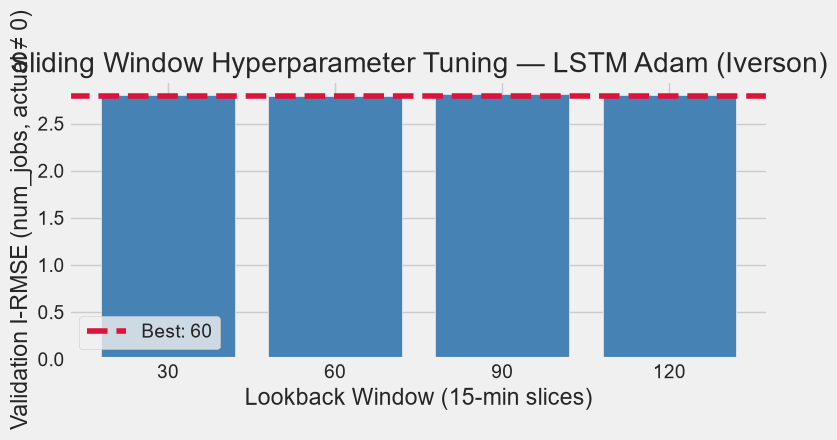

In [14]:
# Visualize sliding window tuning results
window_df = pd.DataFrame(window_tuning_results_lstm_adam, columns=['Window Size', 'Validation I-RMSE'])
plt.figure(figsize=(8, 4))
plt.bar(window_df['Window Size'].astype(str), window_df['Validation I-RMSE'], color='steelblue')
plt.axhline(best_window_val_rmse_lstm_adam, color='crimson', linestyle='--', label=f'Best: {best_window_size_lstm_adam}')
plt.title('Sliding Window Hyperparameter Tuning — LSTM Adam (Iverson)')
plt.xlabel('Lookback Window (15-min slices)')
plt.ylabel('Validation I-RMSE (num_jobs, actual ≠ 0)')
plt.legend()
plt.tight_layout()
plt.show()

### GRU Adam Window Tuning

In [15]:
window_tuning_results_gru_adam = []
best_window_size_gru_adam = WINDOW_CANDIDATES[0]
best_window_val_rmse_gru_adam = float('inf')

In [16]:
print('Tuning sliding window on validation Iverson RMSE...')
for candidate_window in WINDOW_CANDIDATES:
    x_tune_train, y_tune_train = create_sequences(full_data, candidate_window, 0, train_end, target_idx)
    x_tune_val, y_tune_val = create_sequences(full_data, candidate_window, train_end, val_end, target_idx)

    tune_model = build_model('GRU', Adam(learning_rate=0.001), candidate_window, n_features, target_idx, mean_lr=DAIN_MEAN_LR, gate_lr=DAIN_GATE_LR, scale_lr=DAIN_SCALE_LR)
    tune_model.fit(
        x_tune_train, y_tune_train,
        validation_data=(x_tune_val, y_tune_val),
        batch_size=32,
        epochs=50,
        verbose=0,
        # callbacks=training_callbacks
    )

    val_pred = make_predictions(tune_model, x_tune_val, target_idx)
    candidate_val_rmse = iverson_rmse(y_tune_val, val_pred)
    window_tuning_results_gru_adam.append((candidate_window, candidate_val_rmse))
    print(f'  window={candidate_window:3d} -> validation I-RMSE: {candidate_val_rmse:.4f}')

    if candidate_val_rmse < best_window_val_rmse_gru_adam:
        best_window_val_rmse_gru_adam = candidate_val_rmse
        best_window_size_gru_adam = candidate_window

print(f'\nSelected sliding window: {best_window_size_gru_adam} (validation I-RMSE: {best_window_val_rmse_gru_adam:.4f})')

x_train_gru_adam, y_train_gru_adam = create_sequences(full_data, best_window_size_gru_adam, 0, train_end, target_idx)
x_val_gru_adam, y_val_gru_adam = create_sequences(full_data, best_window_size_gru_adam, train_end, val_end, target_idx)
x_test_gru_adam, y_test_gru_adam = create_sequences(full_data, best_window_size_gru_adam, val_end, len(full_data), target_idx)

print('Data preparation completed.')
print(f'Train samples: {len(x_train_gru_adam)}, Val samples: {len(x_val_gru_adam)}, Test samples: {len(x_test_gru_adam)}')


Tuning sliding window on validation Iverson RMSE...


c:\KSAK\.venv\Lib\site-packages\keras\src\layers\layer.py:431: UserWarning: `build()` was called on layer 'DAINLayer', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


  window= 30 -> validation I-RMSE: 2.7842
  window= 60 -> validation I-RMSE: 2.7900
  window= 90 -> validation I-RMSE: 2.7755
  window=120 -> validation I-RMSE: 2.7627

Selected sliding window: 120 (validation I-RMSE: 2.7627)
Data preparation completed.
Train samples: 48893, Val samples: 10383, Test samples: 10382


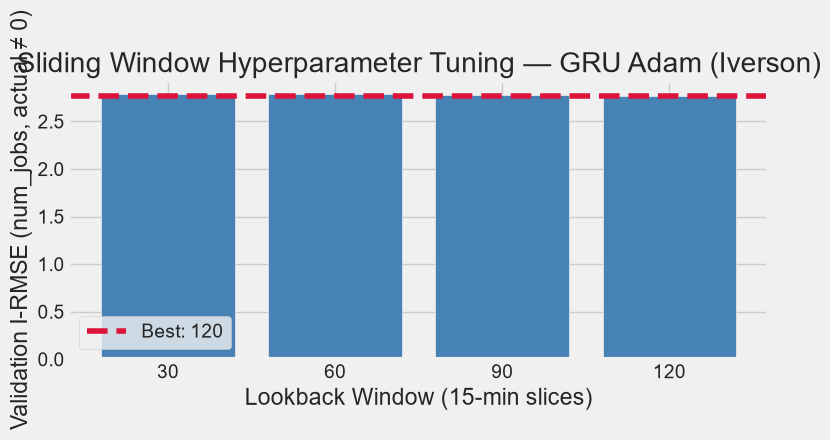

In [17]:
# Visualize sliding window tuning results
window_df = pd.DataFrame(window_tuning_results_gru_adam, columns=['Window Size', 'Validation I-RMSE'])
plt.figure(figsize=(8, 4))
plt.bar(window_df['Window Size'].astype(str), window_df['Validation I-RMSE'], color='steelblue')
plt.axhline(best_window_val_rmse_gru_adam, color='crimson', linestyle='--', label=f'Best: {best_window_size_gru_adam}')
plt.title('Sliding Window Hyperparameter Tuning — GRU Adam (Iverson)')
plt.xlabel('Lookback Window (15-min slices)')
plt.ylabel('Validation I-RMSE (num_jobs, actual ≠ 0)')
plt.legend()
plt.tight_layout()
plt.show()


## Step 4: Training Models and Evaluating Performance


In [18]:
# BATCH_SIZE and EPOCHS are set in the CONFIG cell.
print(f'batch={BATCH_SIZE} epochs={EPOCHS}')


batch=32 epochs=50


**Training LSTM with Adam**

In [19]:
# LSTM with Adam
optimizer_adam = Adam(learning_rate=0.001)
model_lstm_adam = build_model('LSTM', optimizer_adam, best_window_size_lstm_adam, n_features, target_idx, mean_lr=DAIN_MEAN_LR, gate_lr=DAIN_GATE_LR, scale_lr=DAIN_SCALE_LR)
history_lstm_adam = model_lstm_adam.fit(
    x_train_lstm_adam, y_train_lstm_adam,
    validation_data=(x_val_lstm_adam, y_val_lstm_adam),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    # callbacks=training_callbacks,
    verbose=1
)
print('LSTM with Adam training completed.')


c:\KSAK\.venv\Lib\site-packages\keras\src\layers\layer.py:431: UserWarning: `build()` was called on layer 'DAINLayer', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Epoch 1/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 79s 47ms/step - loss: 0.8856 - val_loss: 0.4085
Epoch 2/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 73s 48ms/step - loss: 0.8429 - val_loss: 0.4169
Epoch 3/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 72s 47ms/step - loss: 0.8354 - val_loss: 0.4203
Epoch 4/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 73s 48ms/step - loss: 0.8271 - val_loss: 0.4109
Epoch 5/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 75s 49ms/step - loss: 0.8186 - val_loss: 0.4499
Epoch 6/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 72s 47ms/step - loss: 0.8141 - val_loss: 0.4085
Epoch 7/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 72s 47ms/step - loss: 0.8039 - val_loss: 0.4038
Epoch 8/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 79s 52ms/step - loss: 0.7901 - val_loss: 0.4207
Epoch 9/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 77s 50ms/step - loss: 0.7847 - val_loss: 0.4088
Epoch 10/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 80s 49ms/step - loss: 0.7747 - val_loss: 0.4112
Epoch 11/50
1530/1530 ━━━━━━━━━━━━━━━━━━━━ 84s 55ms/step - loss: 0.7662 - val_loss: 0.4065
Epoch 12

**Training GRU with Adam**


In [20]:
# GRU with Adam
optimizer_adam_gru = Adam(learning_rate=0.001)
model_gru_adam = build_model('GRU', optimizer_adam_gru, best_window_size_gru_adam, n_features, target_idx, mean_lr=DAIN_MEAN_LR, gate_lr=DAIN_GATE_LR, scale_lr=DAIN_SCALE_LR)
history_gru_adam = model_gru_adam.fit(
    x_train_gru_adam, y_train_gru_adam,
    validation_data=(x_val_gru_adam, y_val_gru_adam),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    # callbacks=training_callbacks,
    verbose=1
)
print('GRU with Adam training completed.')


Epoch 1/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 204s 128ms/step - loss: 0.8713 - val_loss: 0.4082
Epoch 2/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 185s 121ms/step - loss: 0.8502 - val_loss: 0.4104
Epoch 3/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 182s 119ms/step - loss: 0.8355 - val_loss: 0.4089
Epoch 4/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 200s 131ms/step - loss: 0.8326 - val_loss: 0.4104
Epoch 5/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 211s 138ms/step - loss: 0.8213 - val_loss: 0.4114
Epoch 6/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 211s 138ms/step - loss: 0.8116 - val_loss: 0.4121
Epoch 7/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 179s 117ms/step - loss: 0.8030 - val_loss: 0.4136
Epoch 8/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 119s 78ms/step - loss: 0.7875 - val_loss: 0.4182
Epoch 9/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 112s 73ms/step - loss: 0.7886 - val_loss: 0.4227
Epoch 10/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 112s 73ms/step - loss: 0.7782 - val_loss: 0.4145
Epoch 11/50
1528/1528 ━━━━━━━━━━━━━━━━━━━━ 112s 73ms/step - loss: 0.7587 - val_los

KeyboardInterrupt: 

## Step 4: Making Predictions and Evaluating Models


In [ ]:
# Predictions are inverted with the train-only global target mean/std used during training.
# Metrics use Iverson's bracket: only time slices where actual num_jobs != 0 are scored.
y_test_actual_lstm_adam = y_test_lstm_adam
y_test_actual_gru_adam = y_test_gru_adam

pred_lstm_adam = make_predictions(model_lstm_adam, x_test_lstm_adam, target_idx)
pred_gru_adam = make_predictions(model_gru_adam, x_test_gru_adam, target_idx)

metrics_values = {
    'LSTM Adam': {
        'I-MSE': iverson_mse(y_test_actual_lstm_adam, pred_lstm_adam),
        'I-RMSE': iverson_rmse(y_test_actual_lstm_adam, pred_lstm_adam),
        'I-MAE': iverson_mae(y_test_actual_lstm_adam, pred_lstm_adam),
        'I-R2': iverson_r2(y_test_actual_lstm_adam, pred_lstm_adam),
    },
    'GRU Adam': {
        'I-MSE': iverson_mse(y_test_actual_gru_adam, pred_gru_adam),
        'I-RMSE': iverson_rmse(y_test_actual_gru_adam, pred_gru_adam),
        'I-MAE': iverson_mae(y_test_actual_gru_adam, pred_gru_adam),
        'I-R2': iverson_r2(y_test_actual_gru_adam, pred_gru_adam),
    },
}

print('Predictions and Iverson metric calculations completed.')
for model_name, m in metrics_values.items():
    print(
        f"  {model_name}: I-MSE = {m['I-MSE']:.4f} | I-RMSE = {m['I-RMSE']:.4f} | "
        f"I-MAE = {m['I-MAE']:.4f} | I-R^2 = {m['I-R2']:.4f}"
    )


Predictions and Iverson metric calculations completed.
  LSTM Adam: I-MSE = 1.5864 | I-RMSE = 1.2595 | I-MAE = 0.8511 | I-R^2 = -0.7332
  GRU Adam: I-MSE = 2.8733 | I-RMSE = 1.6951 | I-MAE = 1.0205 | I-R^2 = -2.2199


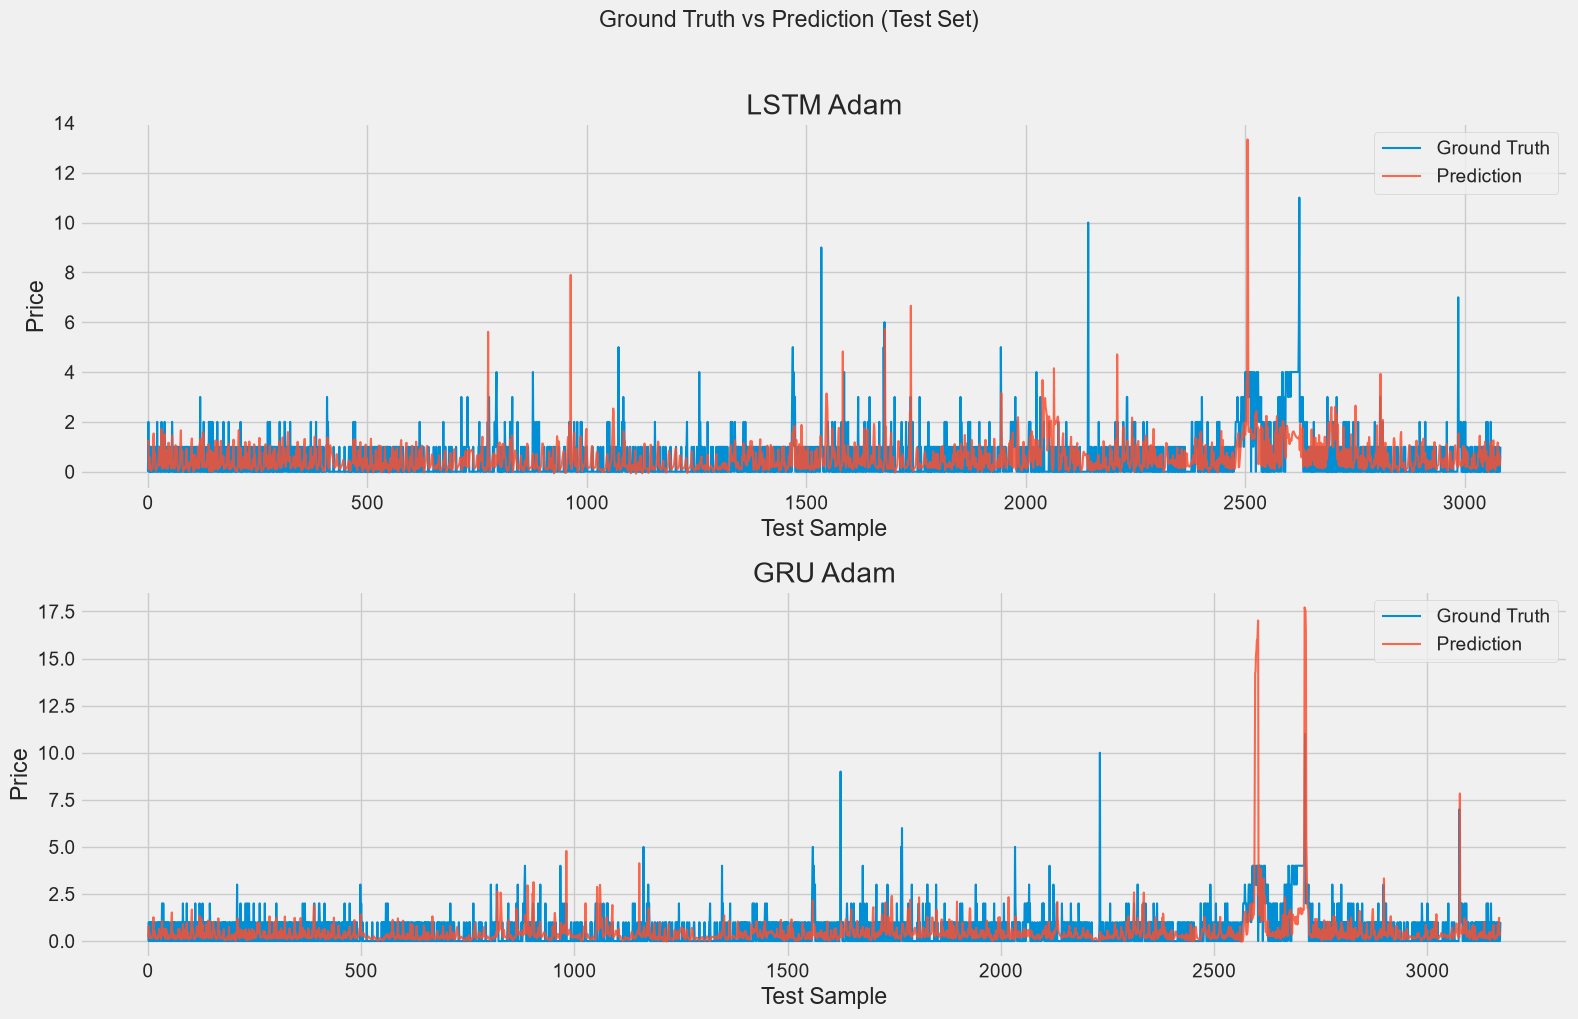

In [ ]:
# Ground truth vs prediction for every model
prediction_plots = [
    ('LSTM Adam', y_test_actual_lstm_adam, pred_lstm_adam),
    ('GRU Adam',  y_test_actual_gru_adam,  pred_gru_adam),
]

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=False)
axes = axes.flatten()

for ax, (name, y_true, y_pred) in zip(axes, prediction_plots):
    ax.plot(y_true, label='Ground Truth', linewidth=1.5)
    ax.plot(y_pred, label='Prediction', linewidth=1.5, alpha=0.85)
    ax.set_title(name)
    ax.set_xlabel('Test Sample')
    ax.set_ylabel('Price')
    ax.legend()

plt.suptitle('Ground Truth vs Prediction (Test Set)', y=1.02)
plt.tight_layout()
plt.show()

## Step 5: Visualizations and Analysis
Visualizations included are:
* Line Plot of Loss vs. Epochs
* Line Plot of Log(Loss) vs. Epochs
* Bar chart of Final loss by Model-Optimizer Combination
* Iverson metrics summary table
* Training and Validation Loss Heatmaps



**Line Plot of Loss vs. Epochs**

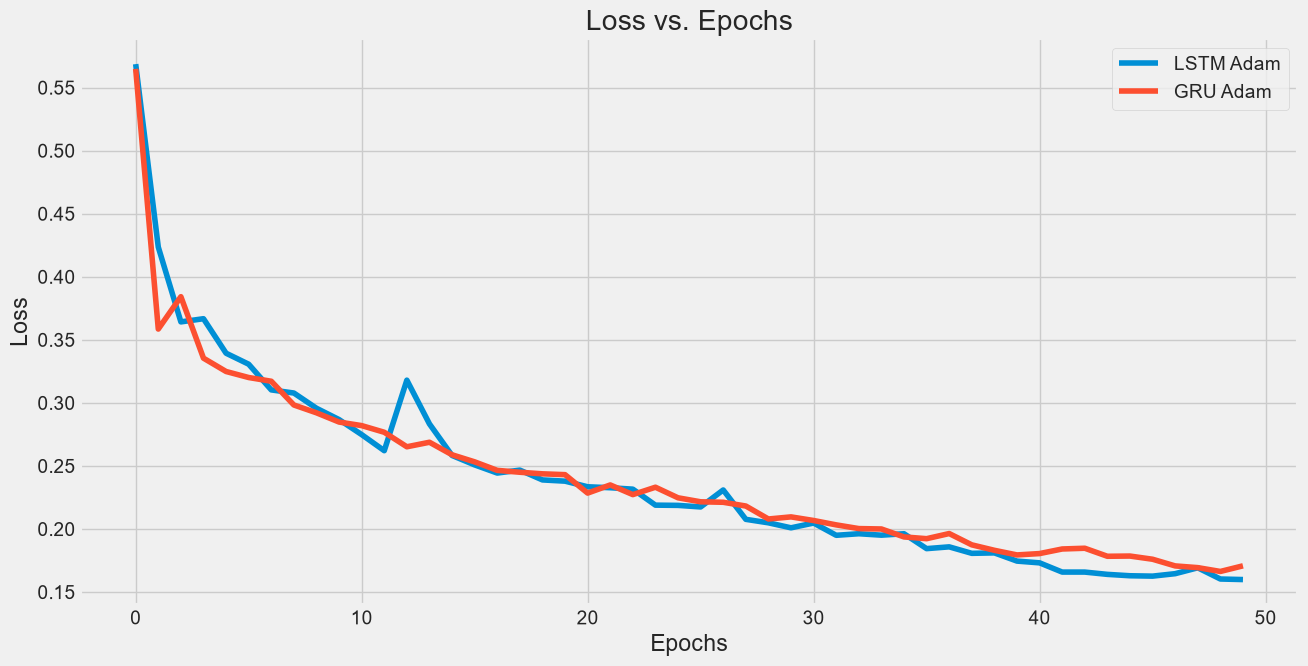

Loss vs. Epochs plot generated.


In [ ]:
# Line Plot of Loss vs. Epochs
plt.figure(figsize=(14, 7))
plt.plot(history_lstm_adam.history['loss'], label='LSTM Adam')
plt.plot(history_gru_adam.history['loss'], label='GRU Adam')
plt.title('Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

print("Loss vs. Epochs plot generated.")

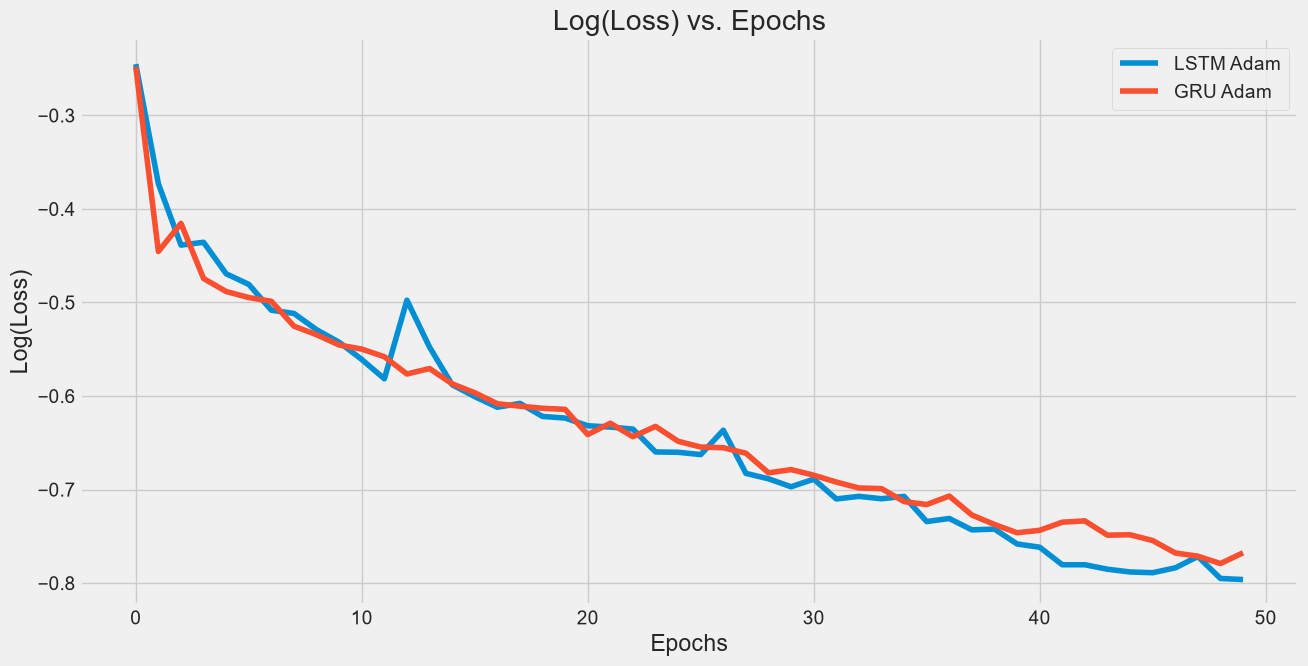

Convergence curves generated.


In [ ]:
# Convergence Curves
plt.figure(figsize=(14, 7))
plt.plot(np.log10(history_lstm_adam.history['loss']), label='LSTM Adam')
plt.plot(np.log10(history_gru_adam.history['loss']), label='GRU Adam')
plt.title('Log(Loss) vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Log(Loss)')
plt.legend()
plt.show()

print("Convergence curves generated.")


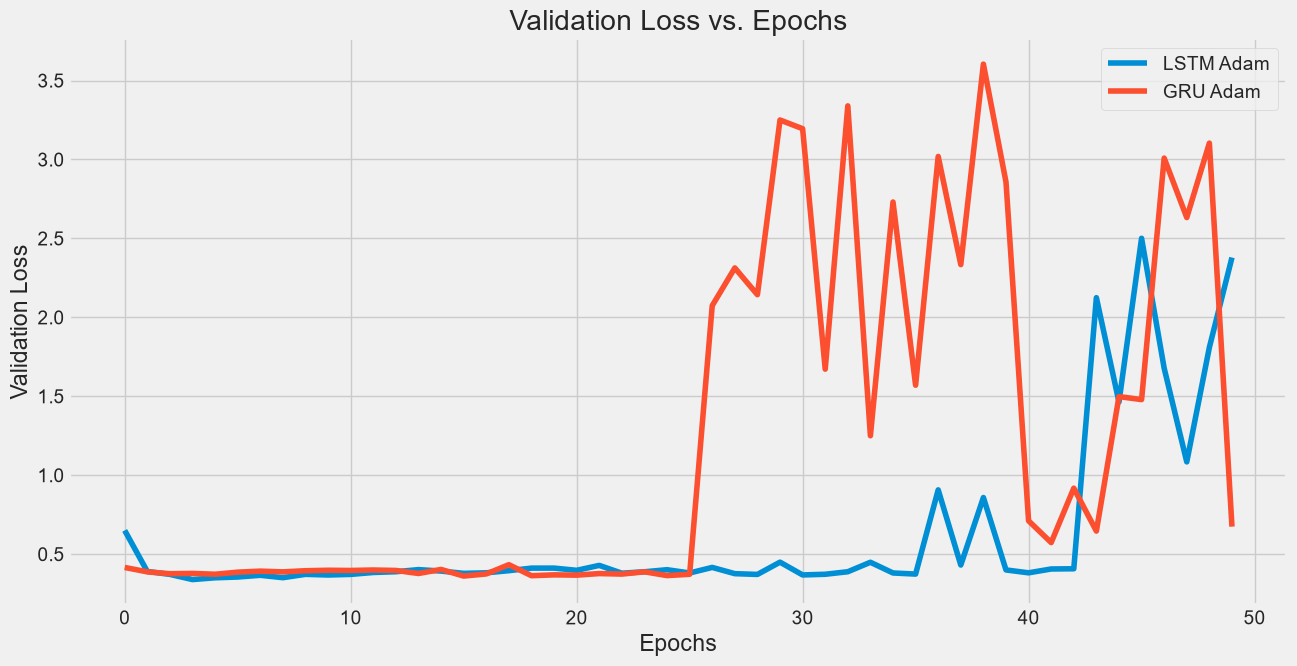

Validation Loss vs. Epochs plot generated.


In [ ]:
# Line Plot of Validation Loss vs. Epochs
plt.figure(figsize=(14, 7))
plt.plot(history_lstm_adam.history['val_loss'], label='LSTM Adam')
plt.plot(history_gru_adam.history['val_loss'], label='GRU Adam')
plt.title('Validation Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.show()

print("Validation Loss vs. Epochs plot generated.")

**Bar Charts of Final Loss**

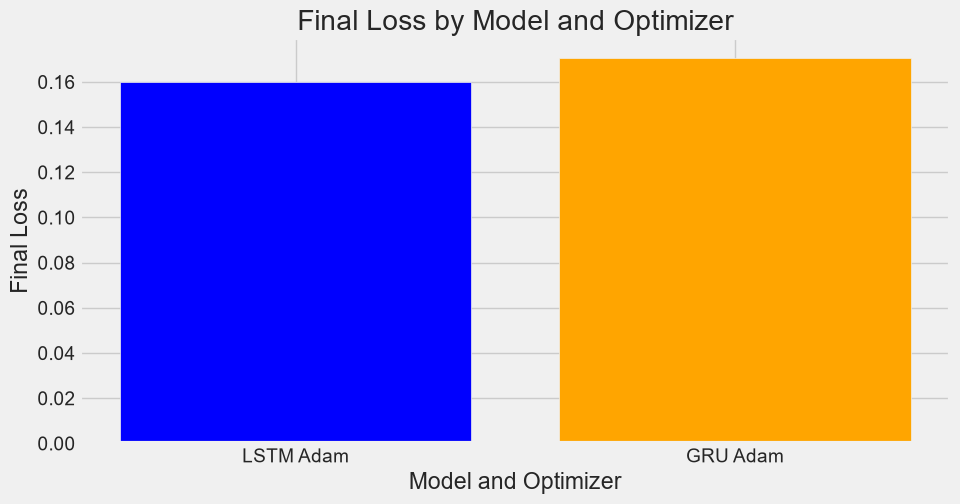

Final Loss bar chart generated.


In [ ]:
# Bar Chart of Final Loss
final_losses = [
    history_lstm_adam.history['loss'][-1],
    history_gru_adam.history['loss'][-1],
]

models = ['LSTM Adam', 'GRU Adam']

plt.figure(figsize=(10, 5))
plt.bar(models, final_losses, color=['blue', 'orange', 'green', 'red'])
plt.title('Final Loss by Model and Optimizer')
plt.xlabel('Model and Optimizer')
plt.ylabel('Final Loss')
plt.show()

print("Final Loss bar chart generated.")


**Iverson Metrics Summary Table**

In [ ]:
# Metrics Summary Table (Iverson brackets: actual != 0)
metrics_table = [
    [
        model,
        f"{m['I-MSE']:.4f}",
        f"{m['I-RMSE']:.4f}",
        f"{m['I-MAE']:.4f}",
        f"{m['I-R2']:.4f}",
    ]
    for model, m in metrics_values.items()
]
print(tabulate(
    metrics_table,
    headers=['Model & Optimizer', 'I-MSE', 'I-RMSE', 'I-MAE', 'I-R^2'],
    tablefmt='pretty'
))

print("Iverson metrics summary table generated.")

+-------------------+--------+--------+--------+---------+
| Model & Optimizer | I-MSE  | I-RMSE | I-MAE  |  I-R^2  |
+-------------------+--------+--------+--------+---------+
|     LSTM Adam     | 1.5864 | 1.2595 | 0.8511 | -0.7332 |
|     GRU Adam      | 2.8733 | 1.6951 | 1.0205 | -2.2199 |
+-------------------+--------+--------+--------+---------+
Iverson metrics summary table generated.


## Save results

In [ ]:
# Append one row per model to results.csv
import csv
from datetime import datetime
from sklearn.metrics import r2_score

WINDOWS = {'LSTM Adam': best_window_size_lstm_adam,
           'GRU Adam': best_window_size_gru_adam}

def _iverson_r2(actual, prediction):
    """Only needed for the EDAIN notebook, whose metrics table has no R^2."""
    a = np.asarray(actual, dtype=float).reshape(-1)
    p = np.asarray(prediction, dtype=float).reshape(-1)
    mask = a != 0.0
    return float(r2_score(a[mask], p[mask])) if mask.sum() >= 2 else float('nan')


rows = []
for model_name, m in metrics_values.items():
    r2 = m.get('I-R2')
    if r2 is None:                       # EDAIN: computed here, its own table is untouched
        x_test, y_test_raw = test_sets[model_name]
        r2 = _iverson_r2(y_test_raw, predictions[model_name])
    rows.append({
        'run': RUN_NAME,
        'experiment': 2,
        'method': 'DAIN',
        'backbone': model_name,
        'feature_mode': FEATURE_MODE,
        'target': TARGET_COL,
        'dataset': DATASET,
        'window': WINDOWS[model_name],
        'seed': SEED,
        'I_MSE': round(float(m['I-MSE']), 4),
        'I_RMSE': round(float(m['I-RMSE']), 4),
        'I_MAE': round(float(m['I-MAE']), 4),
        'I_R2': round(float(r2), 4),
        'timestamp': datetime.now().isoformat(timespec='seconds'),
    })

write_header = not os.path.exists(RESULTS_CSV)
with open(RESULTS_CSV, 'a', newline='') as fh:
    writer = csv.DictWriter(fh, fieldnames=list(rows[0]))
    if write_header:
        writer.writeheader()
    writer.writerows(rows)

print(f'Saved {len(rows)} row(s) to {RESULTS_CSV}:')
for r in rows:
    print(f"  {r['backbone']:18s} window={r['window']:3d}  "
          f"I-RMSE={r['I_RMSE']:.4f}  I-MAE={r['I_MAE']:.4f}  I-R2={r['I_R2']:.4f}")


Saved 2 row(s) to results.csv:
  LSTM Adam          window=120  I-RMSE=1.2595  I-MAE=0.8511  I-R2=-0.7332
  GRU Adam           window= 30  I-RMSE=1.6951  I-MAE=1.0205  I-R2=-2.2199
